In [1]:
import pandas as pd
import numpy as np
from scipy.stats import pearsonr, spearmanr
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('palmerpenguins.csv')

df.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,diet,life_stage,health_metrics,year
0,Adelie,Biscoe,53.4,17.8,219.0,5687.0,female,fish,adult,overweight,2021
1,Adelie,Biscoe,49.3,18.1,245.0,6811.0,female,fish,adult,overweight,2021
2,Adelie,Biscoe,55.7,16.6,226.0,5388.0,female,fish,adult,overweight,2021
3,Adelie,Biscoe,38.0,15.6,221.0,6262.0,female,fish,adult,overweight,2021
4,Adelie,Biscoe,60.7,17.9,177.0,4811.0,female,fish,juvenile,overweight,2021


In [3]:
numeric = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']

In [4]:
df['year'] = df['year'].astype('category')
df['sex'] = df['sex'].astype('category')
df['diet'] = df['diet'].astype('category')
df['life_stage'] = df['life_stage'].astype('category')
df['health_metrics'] = df['health_metrics'].astype('category')

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3430 entries, 0 to 3429
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype   
---  ------             --------------  -----   
 0   species            3430 non-null   str     
 1   island             3430 non-null   str     
 2   bill_length_mm     3430 non-null   float64 
 3   bill_depth_mm      3430 non-null   float64 
 4   flipper_length_mm  3430 non-null   float64 
 5   body_mass_g        3430 non-null   float64 
 6   sex                3430 non-null   category
 7   diet               3430 non-null   category
 8   life_stage         3430 non-null   category
 9   health_metrics     3430 non-null   category
 10  year               3430 non-null   category
dtypes: category(5), float64(4), str(2)
memory usage: 177.8 KB


<Figure size 1000x600 with 0 Axes>

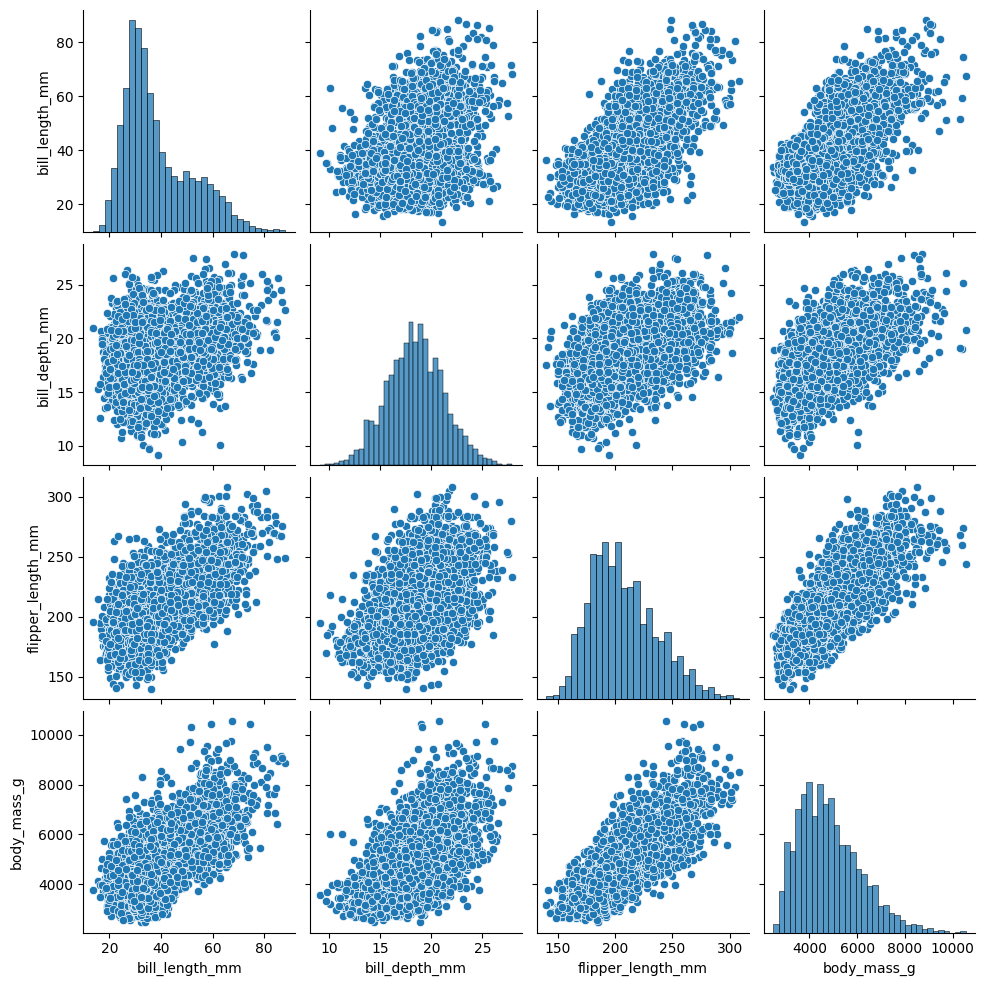

In [6]:
plt.figure(figsize=(10, 6))
sns.pairplot(df[numeric])
plt.show()

In [7]:
results = []
for i in range(len(numeric)):
    for j in range(i + 1, len(numeric)):
        c1, c2 = numeric[i], numeric[j]
        p_r, p_p = pearsonr(df[c1], df[c2])
        s_r, s_p = spearmanr(df[c1], df[c2])
        results.append({
            'Pair': f"{c1} & {c2}",
            'Pearson r': p_r,
            'Pearson p-val': p_p,
            'Spearman rho': s_r,
            'Spearman p-val': s_p
        })

summary_df = pd.DataFrame(results)
summary_df

,Pair,Pearson r,Pearson p-val,Spearman rho,Spearman p-val
0,bill_length_mm & bill_depth_mm,0.312916,8.529782e-79,0.267523,2.682568e-57
1,bill_length_mm & flipper_length_mm,0.669066,0.000000e+00,0.586937,0.000000e+00
2,bill_length_mm & body_mass_g,0.661170,0.000000e+00,0.562029,6.386959e-285
3,bill_depth_mm & flipper_length_mm,0.487376,3.717404e-204,0.494696,3.257336e-211
4,bill_depth_mm & body_mass_g,0.558539,1.122440e-280,0.567215,2.520376e-291
5,flipper_length_mm & body_mass_g,0.792182,0.000000e+00,0.792706,0.000000e+00


<pre>
Flipper_length_mm and body_mass_g has a strongest correlation among all numeric pairs which is 0.792 both close in pearson r and spearman rho.  
But in general bill_length_mm & flipper_length_mm, bill_length_mm & body_mass_g, bill_depth_mm & body_mass_g have a strong correlation >0.5 too. 
For bill_length_mm & flipper_length_mm, bill_length_mm & body_mass_g pearson and spearman values diasgree to some extent, 0.669-0.586 and 0.661-0.562 respectively. 
The cause of this diasgreement can be out of non-linearity, although theres a relation between the features, it's possible that they have non-linear one.
</pre>

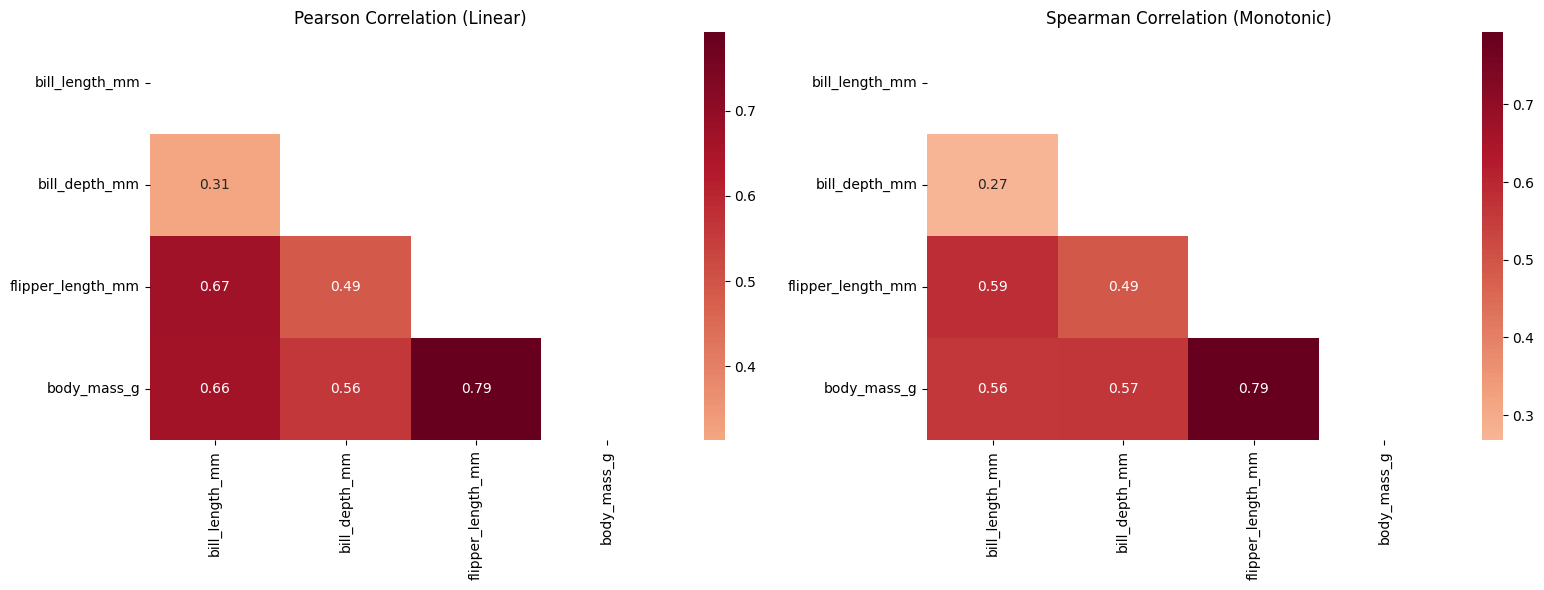

In [8]:
pearson_mtx = df[numeric].corr(method='pearson')
spearman_mtx = df[numeric].corr(method='spearman')

mask = np.triu(np.ones_like(pearson_mtx, dtype=bool))

fig, ax = plt.subplots(1, 2, figsize=(16, 6))

sns.heatmap(pearson_mtx, mask=mask, annot=True, fmt=".2f", 
            cmap='RdBu_r', center=0, ax=ax[0])
ax[0].set_title('Pearson Correlation (Linear)')

sns.heatmap(spearman_mtx, mask=mask, annot=True, fmt=".2f", 
            cmap='RdBu_r', center=0, ax=ax[1])
ax[1].set_title('Spearman Correlation (Monotonic)')

plt.tight_layout()
plt.show()



#### Does the regression line capture the actual pattern well?
For the **flipper length vs. body mass** pair, the global regression line captures the pattern very well because the trend is consistent across all penguins. However, for pairs involving **bill dimensions**, the global regression line is often misleading. It attempts to draw a single line through three distinct species clusters that actually have different biological proportions.

#### Do subgroups show different slopes or intercepts?
Yes, the subgroups (species) show significantly different **intercepts**. For example, at the same bill length, a Gentoo penguin will typically have a much smaller bill depth than an Adelie. While the **slopes** (the rate of change) are often similar across species, the species-specific regression lines are offset from one another, highlighting that each species has its own unique "build" or morphometrics.

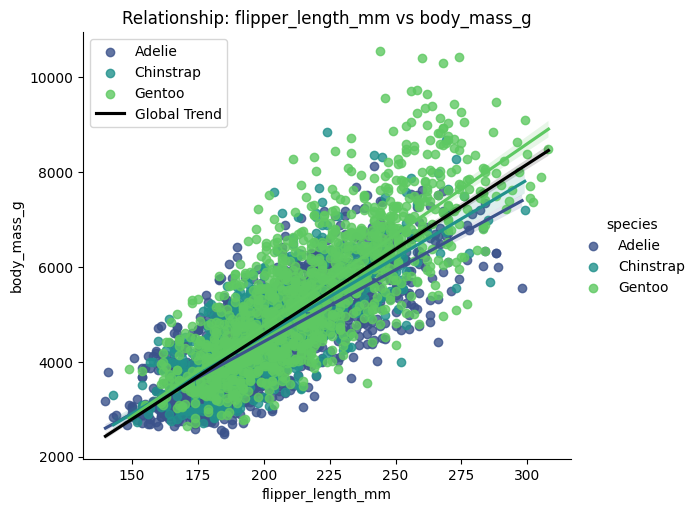

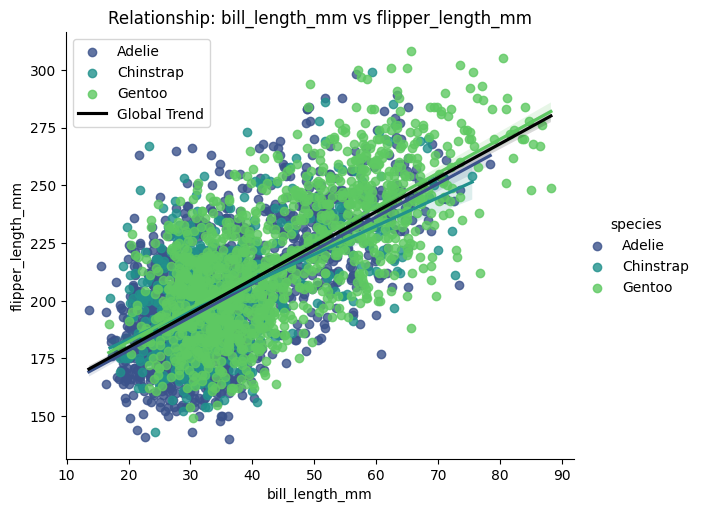

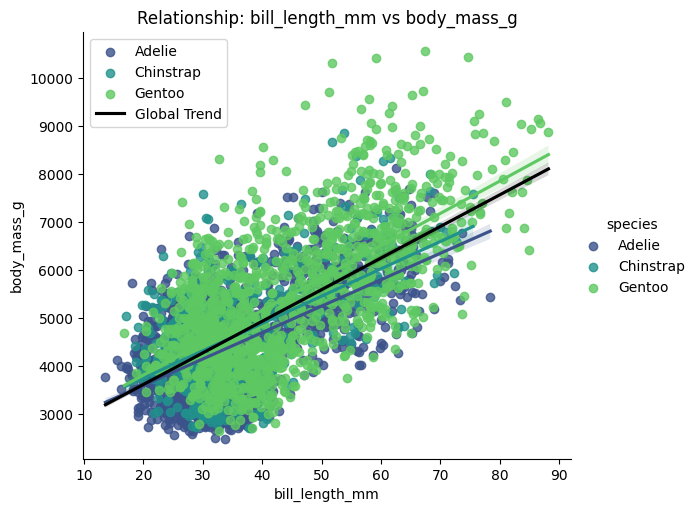

In [9]:
top_3 = summary_df.iloc[summary_df['Pearson r'].abs().nlargest(3).index]

for _, row in top_3.iterrows():
    c1, c2 = row['Pair'].split(' & ')
    
    g = sns.lmplot(data=df, x=c1, y=c2, hue='species', 
                   height=5, aspect=1.2, palette='viridis')
    
    sns.regplot(data=df, x=c1, y=c2, scatter=False, 
                color='black', label='Global Trend', ax=g.ax)
    
    plt.title(f"Relationship: {c1} vs {c2}")
    plt.legend()
    plt.show()

### Task 3: Scatterplot Analysis Discussion

#### 1. Does the regression line capture the actual pattern well?
For pairs like **flipper_length_mm vs. body_mass_g**, the regression line captures the pattern exceptionally well. There is a clear, consistent linear trend across the entire dataset. However, for pairs involving **bill_depth_mm**, a single global regression line (the black dashed line) often fails to represent the data accurately. It tends to "smear" across distinct clusters, missing the nuance of how individual species are built.

#### 2. Do subgroups show different slopes or intercepts?
The scatterplots reveal significant differences in **intercepts** between species. For instance:
* **Intercepts:** At any given bill length, a *Gentoo* penguin consistently has a smaller bill depth than an *Adelie* or *Chinstrap*. This creates vertical offsets between the groups.
* **Slopes:** Interestingly, the slopes for each species are often quite similar (parallel), suggesting that the biological growth rate between these body parts is consistent across species, even if their starting proportions (intercepts) differ.
* **Simpson's Paradox:** The bill length vs. bill depth pair is a classic example of Simpson's Paradox; the global trend might appear negative or flat, but within each species subgroup, the relationship is actually positive.